# Exploração: distribuição de frames rotulados

Cada vídeo do dataset possui todos os seus frames extraídos em disco, mas apenas um
subconjunto esparso desses frames possui rótulo (máscara de segmentação) associado
(ver `inca-video-frame-dataset.csv`). Este notebook explora, por vídeo, a esparsidade
dessa rotulação:

- Quantidade de frames e de rótulos por vídeo.
1. **Histograma dos gaps entre frames rotulados consecutivos** (dentro de cada vídeo).
2. **Distância até o rótulo mais próximo**: para cada frame extraído do dataset, a
   distância até o frame rotulado mais próximo do mesmo vídeo.
3. **Frames e rótulos fora do intervalo "entre dois rótulos"**: frames que ficam *antes
   do primeiro* ou *depois do último* frame rotulado do vídeo (portanto fora do
   intervalo `[min(rotulado), max(rotulado)]`), e, de forma análoga, rótulos que não têm
   outro rótulo antes *e* depois deles no mesmo vídeo (ou seja, o primeiro e o último
   rótulo de cada vídeo).

A maioria dos histogramas é mostrada em par: **distribuição** (eixo y = % das
unidades — vídeos, gaps ou frames — naquele bin) e **acumulado** (eixo y = % das
unidades até aquele valor), o que permite leituras diretas do tipo "70% dos vídeos têm
até 4 rótulos" ou "Y% dos gaps entre rótulos são de até 40 frames".

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
sys.path.append('../')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Parâmetros

- `DATASET_PATH`: diretório raiz do dataset (mesmo formato usado por `VFSSWindowImageDataset`).
- `VIDEO_FRAME_TABLE_FILENAME`: nome do CSV com os frames rotulados.
- `*_BIN_WIDTH`: largura dos bins dos histogramas de grandezas inteiras (gaps,
  distância ao rótulo mais próximo e quantidade de rótulos por vídeo), para alinhar os
  bins aos valores inteiros.
- `*_N_BINS`: número de bins dos histogramas de grandezas contínuas (quantidade de
  frames por vídeo e proporções).
- `GAP_THRESHOLD_EXAMPLE`: valor de gap (em frames) usado para anotar, no gráfico
  acumulado de gaps, a leitura "Y% dos gaps são de até X frames".

In [3]:
DATASET_PATH = "/data_ssd/caioseda/data/dataset_inca_all_frames"
VIDEO_FRAME_TABLE_FILENAME = "inca-video-frame-dataset.csv"

# Larguras de bin (grandezas inteiras)
GAP_BIN_WIDTH = 1
N_LABELED_BIN_WIDTH = 1
DISTANCE_BIN_WIDTH = 1

# Números de bins (grandezas contínuas)
FRAMES_PER_VIDEO_N_BINS = 30
FRAMES_OUTSIDE_PROP_N_BINS = 30
LABELS_OUTSIDE_PROP_N_BINS = 20

# Valor de exemplo para anotar o gráfico acumulado de gaps
GAP_THRESHOLD_EXAMPLE = 40

## Carregamento

Lemos o CSV de frames rotulados e, para cada vídeo, contamos o total de frames
extraídos em disco (os frames são numerados de forma contígua de `1` a `total_frames`,
como assumido por `VFSSWindowImageDataset.get_total_frames_in_video`).

In [4]:
df = pd.read_csv(os.path.join(DATASET_PATH, VIDEO_FRAME_TABLE_FILENAME))
df['frame_id'] = df['frame_id'].astype(int)
df['video_id'] = df['video_id'].astype(int)

print(f"Total de amostras rotuladas: {len(df)}")
print(f"Total de vídeos: {df['video_id'].nunique()}")
df.head()

Total de amostras rotuladas: 961
Total de vídeos: 232


,video_frame,video_id,frame_id,batch,selected_labeler,video_path,target_dir,has_mask,has_points,labelers,fonte_dados,paciente_id,momento,procedimento,split_legado,image_path,target_variant,target_path
0,v100_f10,100,10,5,VC,videos/100.avi,rotulos/anotacoes-tecgraf-corrigidas/batch-5/V...,True,True,"['CS', 'VC']",video100,115,pos,total,train,frames/100/10.png,raw,targets/mask/raw/VC/v100_f10.tif
1,v100_f12,100,12,2,AM,videos/100.avi,rotulos/anotacoes-tecgraf-corrigidas/batch-2/A...,True,True,"['AM', 'BB']",video100,115,pos,total,train,frames/100/12.png,raw,targets/mask/raw/AM/v100_f12.tif
2,v100_f13,100,13,3,BB,videos/100.avi,rotulos/anotacoes-tecgraf-corrigidas/batch-3/B...,True,True,"['AM', 'BB']",video100,115,pos,total,train,frames/100/13.png,raw,targets/mask/raw/BB/v100_f13.tif
3,v100_f14,100,14,4,BB,videos/100.avi,rotulos/anotacoes-tecgraf-corrigidas/batch-4/B...,True,True,"['AM', 'BB']",video100,115,pos,total,train,frames/100/14.png,raw,targets/mask/raw/BB/v100_f14.tif
4,v100_f15,100,15,5,VC,videos/100.avi,rotulos/anotacoes-tecgraf-corrigidas/batch-5/V...,True,True,"['AM', 'VC']",video100,115,pos,total,train,frames/100/15.png,raw,targets/mask/raw/VC/v100_f15.tif


In [5]:
def count_total_frames(image_path: str) -> int:
    """Conta os frames extraídos em disco para o vídeo dono de `image_path`."""
    folder = os.path.join(DATASET_PATH, os.path.dirname(image_path))
    return len([f for f in os.listdir(folder) if f.endswith('.png')])


video_info = (
    df.groupby('video_id')
    .agg(image_path=('image_path', 'first'), labeled_frame_ids=('frame_id', lambda s: sorted(s.tolist())))
    .reset_index()
)
video_info['total_frames'] = video_info['image_path'].apply(count_total_frames)
video_info['n_labeled'] = video_info['labeled_frame_ids'].apply(len)

video_info.head()

,video_id,image_path,labeled_frame_ids,total_frames,n_labeled
0,1,frames/1/171.png,"[82, 83, 84, 85, 171]",182,5
1,2,frames/2/106.png,"[88, 106, 112, 150]",163,4
2,3,frames/3/17.png,"[6, 17, 37, 69]",122,4
3,4,frames/4/41.png,"[41, 45, 46, 67]",131,4
4,5,frames/5/135.png,"[27, 135, 144, 169]",256,4


## Função auxiliar de plotagem

`plot_distribution_pct` plota, lado a lado, a distribuição percentual de uma grandeza
(eixo y = % das unidades naquele bin) e sua versão acumulada (eixo y = % das unidades
até aquele valor). É reutilizada em todos os histogramas abaixo para permitir leituras
diretas do tipo "X% dos vídeos têm até N rótulos".

In [6]:
def plot_distribution_pct(data, bins, xlabel, unit_label, title, figsize=(12, 5)):
    """Plota a distribuição percentual de `data` e sua versão acumulada, lado a lado.

    `unit_label` nomeia as unidades sendo contadas (ex.: 'vídeos', 'gaps', 'frames'),
    usado nos rótulos dos eixos y.
    """
    data = np.asarray(data)
    weights = np.full(len(data), 100.0 / len(data))

    fig, axes = plt.subplots(1, 2, figsize=figsize)

    axes[0].hist(data, bins=bins, weights=weights, edgecolor='black')
    axes[0].set_xlabel(xlabel)
    axes[0].set_ylabel(f'% de {unit_label}')
    axes[0].set_title(f'{title} — distribuição')

    axes[1].hist(data, bins=bins, weights=weights, cumulative=True, histtype='step', linewidth=2, color='black')
    axes[1].set_xlabel(xlabel)
    axes[1].set_ylabel(f'% acumulado de {unit_label}')
    axes[1].set_ylim(0, 100)
    axes[1].set_title(f'{title} — acumulado')
    axes[1].grid(alpha=0.3)

    return fig, axes

## Quantidade de frames e de rótulos por vídeo

Antes de olhar para a esparsidade da rotulação, vale entender a distribuição bruta:
quantos frames cada vídeo tem extraídos, e quantos desses frames têm rótulo.

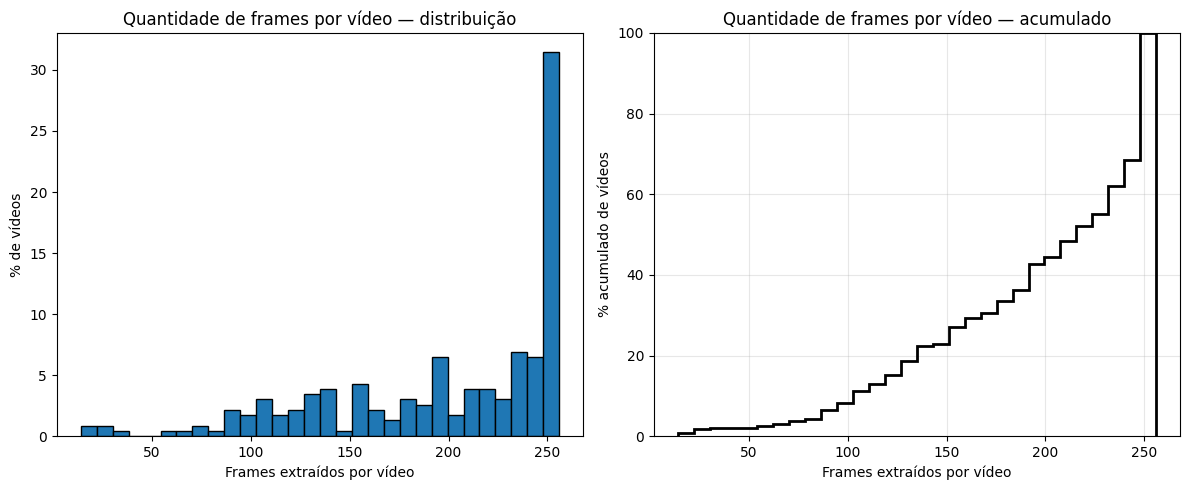

count    232.000000
mean     198.853448
std       60.472634
min       14.000000
25%      155.000000
50%      219.500000
75%      253.250000
max      256.000000
Name: total_frames, dtype: float64


In [7]:
plot_distribution_pct(
    video_info['total_frames'],
    bins=FRAMES_PER_VIDEO_N_BINS,
    xlabel='Frames extraídos por vídeo',
    unit_label='vídeos',
    title='Quantidade de frames por vídeo',
)
plt.tight_layout()
plt.show()

print(video_info['total_frames'].describe())

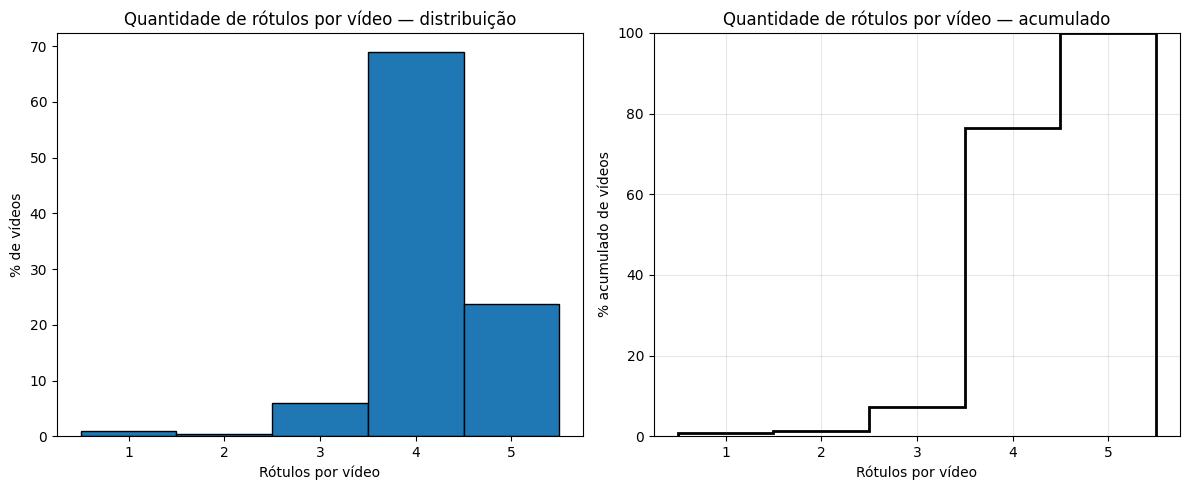

count    232.000000
mean       4.142241
std        0.611244
min        1.000000
25%        4.000000
50%        4.000000
75%        4.000000
max        5.000000
Name: n_labeled, dtype: float64


In [8]:
n_labeled_bins = np.arange(
    video_info['n_labeled'].min(),
    video_info['n_labeled'].max() + 1 + N_LABELED_BIN_WIDTH,
    N_LABELED_BIN_WIDTH,
) - 0.5

plot_distribution_pct(
    video_info['n_labeled'],
    bins=n_labeled_bins,
    xlabel='Rótulos por vídeo',
    unit_label='vídeos',
    title='Quantidade de rótulos por vídeo',
)
plt.tight_layout()
plt.show()

print(video_info['n_labeled'].describe())

In [42]:
# Distribution of the number of videos by the number of labeled frames, with cumulative counts.
video_info.sort_values(by='n_labeled').groupby('n_labeled').agg(n_videos=('video_id', 'count')).cumsum()

# Cumulative sum of the total number of labeled frames across videos, grouped by the number of labeled frames per video.
video_info.sort_values(by='n_labeled').groupby('n_labeled').n_labeled.sum().cumsum()

# if i want to have one code to calculate both:
print(
    video_info
    .sort_values(by='n_labeled')
    .groupby('n_labeled')
    .agg(
        n_videos=('video_id', 'count'),
        n_labeled_frames=('n_labeled', 'sum')
    )
    .cumsum()
)
# to export to text:


           n_videos  n_labeled_frames
n_labeled                            
1                 7                 7
2                30                53
3                95               248
4               214               724
5               231               809


## 1. Distribuição dos gaps entre frames rotulados consecutivos

Para cada vídeo, ordenamos os `frame_id` rotulados e calculamos a diferença entre
frames consecutivos. Um gap de `1` significa frames rotulados adjacentes; gaps maiores
indicam trechos sem rotulação entre dois frames rotulados.

In [17]:
video_info['labeled_frame_ids']

0      [82, 83, 84, 85, 171]
1        [88, 106, 112, 150]
2            [6, 17, 37, 69]
3           [41, 45, 46, 67]
4        [27, 135, 144, 169]
               ...          
226           [65, 142, 171]
227     [113, 149, 169, 214]
228        [12, 15, 51, 188]
229            [6, 111, 214]
230           [84, 190, 234]
Name: labeled_frame_ids, Length: 231, dtype: object

In [9]:
def consecutive_gaps(labeled_frame_ids):
    """Diferenças entre frame_ids rotulados consecutivos (vazio se houver < 2 rótulos)."""
    ids = np.asarray(labeled_frame_ids)
    if len(ids) < 2:
        return np.array([], dtype=int)
    return np.diff(ids)


all_gaps = np.concatenate(video_info['labeled_frame_ids'].apply(consecutive_gaps).to_list())

print(f"Total de gaps observados: {len(all_gaps)}")
print(pd.Series(all_gaps).describe())

Total de gaps observados: 578
count    578.000000
mean      37.425606
std       36.552455
min        1.000000
25%        7.000000
50%       28.000000
75%       57.000000
max      180.000000
dtype: float64


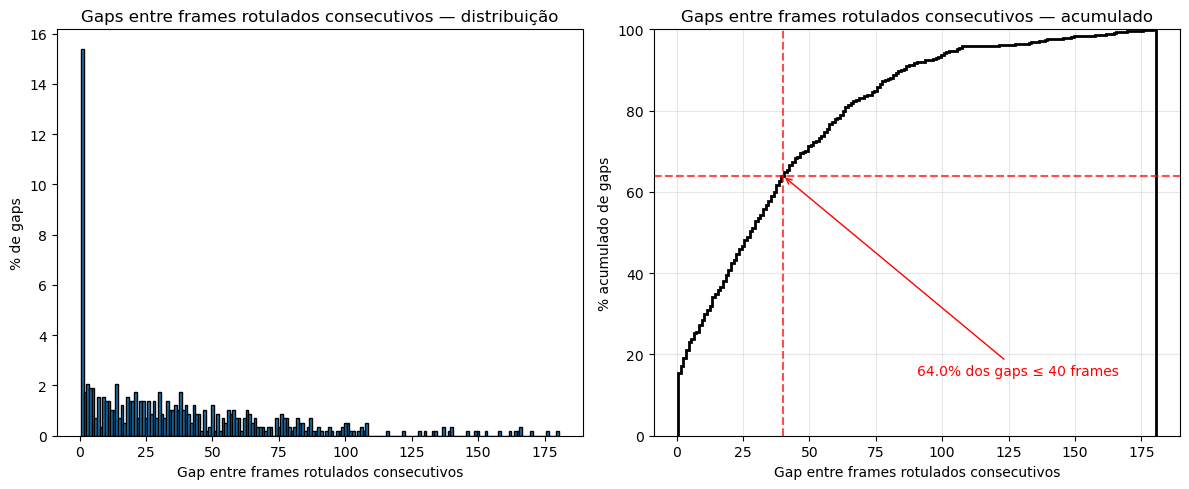

64.0% dos gaps entre rótulos são de até 40 frames.


In [10]:
gap_bins = np.arange(all_gaps.min(), all_gaps.max() + 1 + GAP_BIN_WIDTH, GAP_BIN_WIDTH) - 0.5

fig, axes = plot_distribution_pct(
    all_gaps,
    bins=gap_bins,
    xlabel='Gap entre frames rotulados consecutivos',
    unit_label='gaps',
    title='Gaps entre frames rotulados consecutivos',
)

# Anota no gráfico acumulado a leitura "Y% dos gaps são de até X frames"
pct_le_threshold = 100 * (all_gaps <= GAP_THRESHOLD_EXAMPLE).mean()
axes[1].axhline(pct_le_threshold, color='red', linestyle='--', alpha=0.7)
axes[1].axvline(GAP_THRESHOLD_EXAMPLE, color='red', linestyle='--', alpha=0.7)
axes[1].annotate(
    f'{pct_le_threshold:.1f}% dos gaps ≤ {GAP_THRESHOLD_EXAMPLE} frames',
    xy=(GAP_THRESHOLD_EXAMPLE, pct_le_threshold),
    xytext=(0.5, 0.15),
    textcoords='axes fraction',
    arrowprops=dict(arrowstyle='->', color='red'),
    color='red',
)

plt.tight_layout()
plt.show()

print(f"{pct_le_threshold:.1f}% dos gaps entre rótulos são de até {GAP_THRESHOLD_EXAMPLE} frames.")

## 2. Distância até o rótulo mais próximo

Para cada frame extraído do dataset (não apenas os rotulados), calculamos a distância
(em frames) até o frame rotulado mais próximo do mesmo vídeo. Isso permite leituras
como "a distância média até o rótulo mais próximo é de X frames".

In [11]:
def distances_to_nearest_labeled(total_frames, labeled_frame_ids):
    """Distância (em frames) de cada frame 1..total_frames ao rótulo mais próximo."""
    frames = np.arange(1, total_frames + 1)
    labeled = np.asarray(labeled_frame_ids)
    return np.abs(frames[:, None] - labeled[None, :]).min(axis=1)


all_frame_distances = np.concatenate(
    video_info.apply(
        lambda r: distances_to_nearest_labeled(r.total_frames, r.labeled_frame_ids), axis=1
    ).to_list()
)
mean_dist = all_frame_distances.mean()

print(f"Distância média até o frame rotulado mais próximo: {mean_dist:.2f} frames")
print(pd.Series(all_frame_distances).describe())

Distância média até o frame rotulado mais próximo: 32.93 frames
count    45889.000000
mean        32.930092
std         33.532965
min          0.000000
25%          9.000000
50%         22.000000
75%         46.000000
max        221.000000
dtype: float64


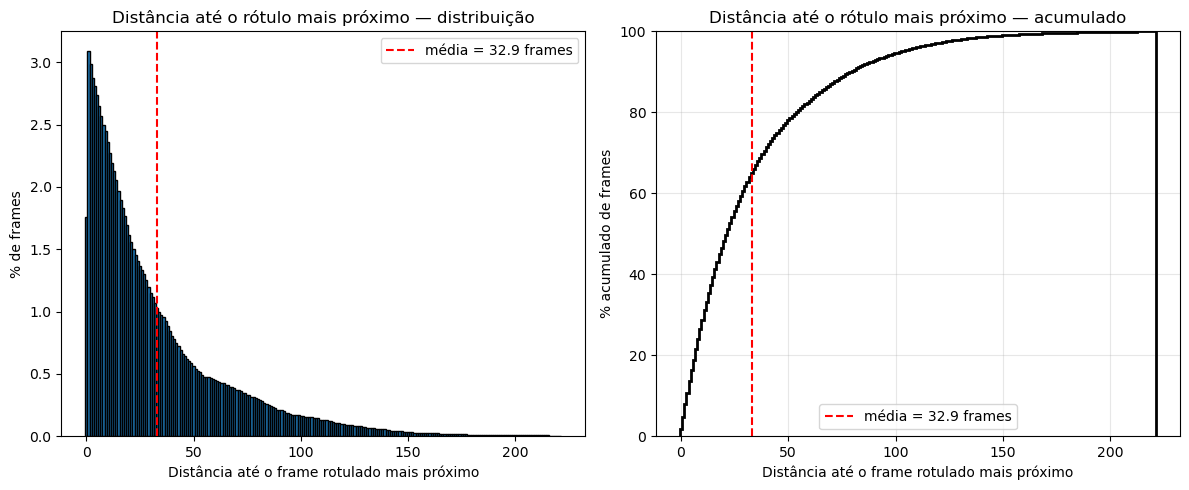

In [12]:
distance_bins = np.arange(
    all_frame_distances.min(), all_frame_distances.max() + 1 + DISTANCE_BIN_WIDTH, DISTANCE_BIN_WIDTH
) - 0.5

fig, axes = plot_distribution_pct(
    all_frame_distances,
    bins=distance_bins,
    xlabel='Distância até o frame rotulado mais próximo',
    unit_label='frames',
    title='Distância até o rótulo mais próximo',
)
for ax in axes:
    ax.axvline(mean_dist, color='red', linestyle='--', label=f'média = {mean_dist:.1f} frames')
    ax.legend()

plt.tight_layout()
plt.show()

## 3. Frames e rótulos fora do intervalo "entre dois rótulos"

Um frame está "entre dois rótulos" quando `min(labeled) <= frame_id <= max(labeled)`.
Frames fora desse intervalo (antes do primeiro ou depois do último rótulo do vídeo) não
têm rótulo "dos dois lados" — apenas extrapolação a partir de um único rótulo na
extremidade. Como o total de frames varia bastante entre vídeos, olhamos para a
**proporção** de frames nessa situação em cada vídeo (medida estática, que não é
enviesada pelo tamanho do vídeo), e reportamos também a quantidade média (absoluta) por
vídeo.

De forma análoga, um rótulo está "entre dois rótulos" quando existe pelo menos um outro
rótulo do mesmo vídeo antes dele *e* pelo menos um depois — ou seja, todo rótulo exceto
o primeiro e o último de cada vídeo (que, com um único rótulo no vídeo, coincidem).
Calculamos também a proporção de rótulos fora dessa condição, por vídeo.

In [13]:
def count_outside_extremes(total_frames, labeled_frame_ids):
    """Conta frames antes do primeiro ou depois do último frame rotulado."""
    first, last = min(labeled_frame_ids), max(labeled_frame_ids)
    before = first - 1
    after = total_frames - last
    return before, after


extremes = video_info.apply(
    lambda r: count_outside_extremes(r.total_frames, r.labeled_frame_ids), axis=1, result_type='expand'
)
extremes.columns = ['frames_before_first_label', 'frames_after_last_label']
video_info = pd.concat([video_info, extremes], axis=1)
video_info['frames_outside_labeled_range'] = (
    video_info['frames_before_first_label'] + video_info['frames_after_last_label']
)
video_info['frames_outside_labeled_range_prop'] = (
    video_info['frames_outside_labeled_range'] / video_info['total_frames']
)

total_outside = video_info['frames_outside_labeled_range'].sum()
total_frames_all = video_info['total_frames'].sum()
avg_count_outside = video_info['frames_outside_labeled_range'].mean()
avg_prop_outside = video_info['frames_outside_labeled_range_prop'].mean()

print(f"Frames fora do intervalo rotulado, no dataset todo: {total_outside} de {total_frames_all} "
      f"({100 * total_outside / total_frames_all:.1f}%)")
print(f"Média por vídeo — quantidade: {avg_count_outside:.1f} frames | proporção: {100 * avg_prop_outside:.1f}%")

Frames fora do intervalo rotulado, no dataset todo: 24026 de 45889 (52.4%)
Média por vídeo — quantidade: 104.0 frames | proporção: 51.3%


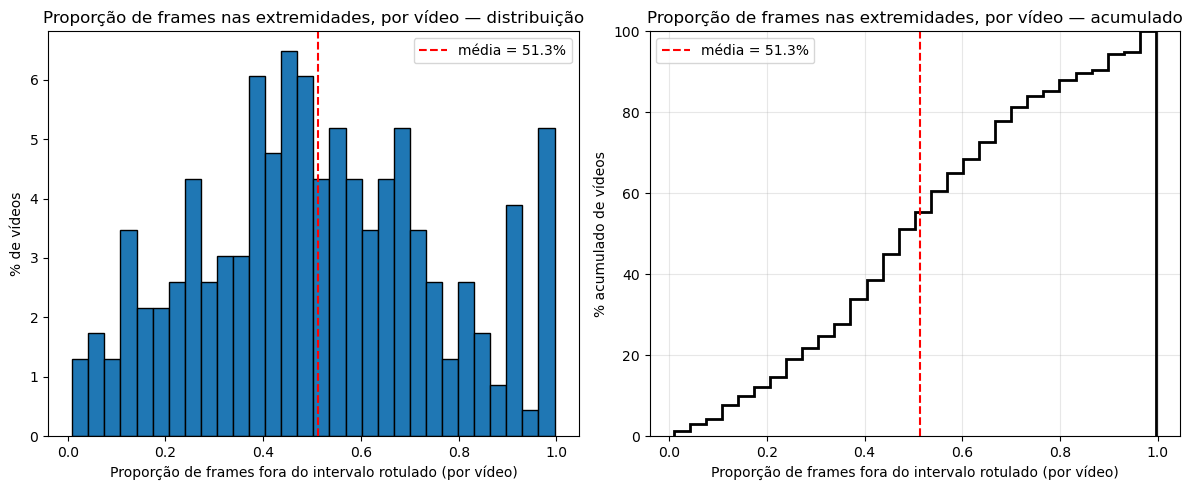

In [14]:
fig, axes = plot_distribution_pct(
    video_info['frames_outside_labeled_range_prop'],
    bins=FRAMES_OUTSIDE_PROP_N_BINS,
    xlabel='Proporção de frames fora do intervalo rotulado (por vídeo)',
    unit_label='vídeos',
    title='Proporção de frames nas extremidades, por vídeo',
)
for ax in axes:
    ax.axvline(avg_prop_outside, color='red', linestyle='--', label=f'média = {100 * avg_prop_outside:.1f}%')
    ax.legend()

plt.tight_layout()
plt.show()

In [15]:
video_info

,video_id,image_path,labeled_frame_ids,total_frames,n_labeled,frames_before_first_label,frames_after_last_label,frames_outside_labeled_range,frames_outside_labeled_range_prop
0,1,train/data/1/171.png,"[82, 83, 84, 85, 171]",182,5,81,11,92,0.505495
1,2,val/data/2/106.png,"[88, 106, 112, 150]",163,4,87,13,100,0.613497
2,3,train/data/3/17.png,"[6, 17, 37, 69]",122,4,5,53,58,0.475410
3,4,test/data/4/41.png,"[41, 45, 46, 67]",131,4,40,64,104,0.793893
4,5,train/data/5/135.png,"[27, 135, 144, 169]",256,4,26,87,113,0.441406
...,...,...,...,...,...,...,...,...,...
226,232,train/data/232/142.png,"[65, 142, 171]",190,3,64,19,83,0.436842
227,233,train/data/233/113.png,"[113, 149, 169, 214]",242,4,112,28,140,0.578512
228,234,test/data/234/12.png,"[12, 15, 51, 188]",221,4,11,33,44,0.199095
229,235,test/data/235/111.png,"[6, 111, 214]",239,3,5,25,30,0.125523
